# Clasificación de CIFAR-10 con una CNN en PyTorch

Construiremos una red convolucional para clasificar imágenes en diez categorías. El ejemplo muestra cómo los filtros locales producen mapas de características que luego usa un clasificador.

## Entorno y datos

Ejecuta este notebook con el kernel **IPD434**. PyTorch usará la GPU CUDA configurada en ese entorno. CIFAR-10 se descarga una vez en `../data/cifar10` y contiene imágenes RGB de $32\times32$ píxeles.

In [1]:
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import classification_report
from torch import nn
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, transforms

SEED = 2026
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Dispositivo:', device)

PyTorch: 2.11.0+cu128
Dispositivo: cuda


## Cargar y preparar CIFAR-10

Normalizamos cada canal RGB y separamos entrenamiento y validación dentro del conjunto de entrenamiento. Usamos subconjuntos para que el ejemplo se ejecute en menos tiempo. La prueba permanece aparte.

In [2]:
DATA_ROOT = Path('../data/cifar10')
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_full = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=transform)
test_full = datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=transform)
split_generator = torch.Generator().manual_seed(SEED)
train_set, val_set, unused = random_split(
    train_full, [15000, 5000, 30000], generator=split_generator
)
test_generator = torch.Generator().manual_seed(SEED + 1)
test_indices = torch.randperm(len(test_full), generator=test_generator)[:5000].tolist()
test_set = Subset(test_full, test_indices)

train_loader = DataLoader(
    train_set, batch_size=128, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), num_workers=0,
    pin_memory=device.type == 'cuda'
)
val_loader = DataLoader(val_set, batch_size=256, shuffle=False, num_workers=0)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=0)
print('Entrenamiento:', len(train_set), '| validación:', len(val_set), '| prueba:', len(test_set))

100.0%


Entrenamiento: 15000 | validación: 5000 | prueba: 5000


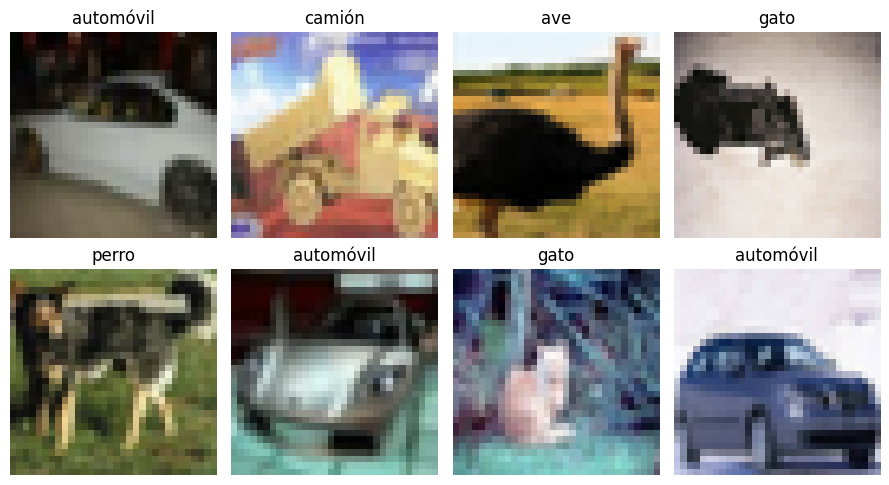

In [3]:
class_names = ['avión', 'automóvil', 'ave', 'gato', 'ciervo',
               'perro', 'rana', 'caballo', 'barco', 'camión']
images, labels = next(iter(DataLoader(train_set, batch_size=8, shuffle=False)))
mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 4, figsize=(9, 5))
for ax, image, label in zip(axes.ravel(), images, labels):
    ax.imshow((image * std + mean).permute(1, 2, 0).clamp(0, 1))
    ax.set_title(class_names[label.item()])
    ax.axis('off')
plt.tight_layout()
plt.show()

## De filtros a predicciones

Una convolución usa pesos compartidos sobre vecindarios de la imagen. Cada filtro produce un mapa de características. El *pooling* reduce su resolución antes de las capas densas.

In [4]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10),
        )

    def forward(self, images):
        return self.network(images)

model = SmallCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
with torch.no_grad():
    print('Forma de salida:', model(torch.zeros(2, 3, 32, 32, device=device)).shape)
print('Parámetros:', sum(p.numel() for p in model.parameters() if p.requires_grad))

Forma de salida: torch.Size([2, 10])
Parámetros: 582026


## Entrenar con validación

La salida contiene diez *logits*. `CrossEntropyLoss` aplica internamente la normalización y compara con etiquetas enteras. Usaremos pérdida de validación para guardar la mejor época.

Época 01 | train_loss=1.7708 | val_loss=1.4497 | val_acc=0.475
Época 02 | train_loss=1.3996 | val_loss=1.2822 | val_acc=0.541
Época 03 | train_loss=1.2330 | val_loss=1.2016 | val_acc=0.569
Época 04 | train_loss=1.1011 | val_loss=1.1305 | val_acc=0.597
Época 05 | train_loss=1.0018 | val_loss=1.0482 | val_acc=0.617
Época 06 | train_loss=0.9033 | val_loss=1.0207 | val_acc=0.641
Época 07 | train_loss=0.8274 | val_loss=1.0427 | val_acc=0.639
Época 08 | train_loss=0.7351 | val_loss=1.0291 | val_acc=0.653
Época 09 | train_loss=0.6482 | val_loss=0.9855 | val_acc=0.665
Época 10 | train_loss=0.5669 | val_loss=0.9976 | val_acc=0.666
Época 11 | train_loss=0.4881 | val_loss=1.0137 | val_acc=0.665
Época 12 | train_loss=0.4136 | val_loss=1.0891 | val_acc=0.675
Detención temprana.


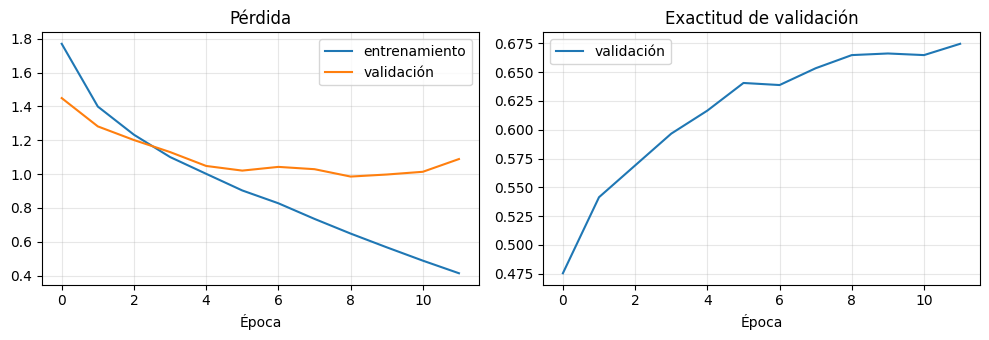

In [5]:
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, correct / total

MAX_EPOCHS, PATIENCE = 12, 3
best_val_loss = float('inf')
best_state = deepcopy(model.state_dict())
waiting = 0
history = {'train_loss': [], 'val_loss': [], 'val_accuracy': []}

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_sum, train_count = 0.0, 0
    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        train_sum += loss.item() * labels.size(0)
        train_count += labels.size(0)

    train_loss = train_sum / train_count
    val_loss, val_accuracy = evaluate(model, val_loader)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_accuracy)
    print(f'Época {epoch:02d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_accuracy:.3f}')

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state = deepcopy(model.state_dict())
        waiting = 0
    else:
        waiting += 1
        if waiting >= PATIENCE:
            print('Detención temprana.')
            break

model.load_state_dict(best_state)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(history['train_loss'], label='entrenamiento')
axes[0].plot(history['val_loss'], label='validación')
axes[0].set(title='Pérdida', xlabel='Época')
axes[1].plot(history['val_accuracy'], label='validación')
axes[1].set(title='Exactitud de validación', xlabel='Época')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Evaluación en prueba

Después de escoger la época con validación, evaluamos una vez el conjunto de prueba y revisamos las métricas por clase.

In [6]:
logits_test, labels_test = [], []
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        logits_test.append(model(images.to(device)).cpu())
        labels_test.append(labels)
logits_test = torch.cat(logits_test).numpy()
y_test = torch.cat(labels_test).numpy()
y_pred = logits_test.argmax(axis=1)
print(classification_report(y_test, y_pred, labels=list(range(10)), target_names=class_names, digits=3, zero_division=0))

              precision    recall  f1-score   support

       avión      0.695     0.739     0.716       482
   automóvil      0.765     0.847     0.804       516
         ave      0.598     0.460     0.520       511
        gato      0.427     0.580     0.492       490
      ciervo      0.573     0.583     0.578       501
       perro      0.622     0.535     0.575       516
        rana      0.801     0.595     0.683       479
     caballo      0.697     0.725     0.711       495
       barco      0.761     0.797     0.779       488
      camión      0.748     0.749     0.748       522

    accuracy                          0.661      5000
   macro avg      0.669     0.661     0.661      5000
weighted avg      0.669     0.661     0.660      5000

